In [ ]:
import kagglehub
import os
import pandas as pd

# Download the latest version of the dataset
path = kagglehub.dataset_download("mahdavi1202/skin-cancer")

print("Path to dataset files:", path)
print("Files in dataset:", os.listdir(path))

# Let's dynamically find and load the CSV file inside the downloaded directory
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print("\nFirst 5 records from", csv_files[0], ":")
    print(df.head())
else:
    print("\nNo CSV files found in the downloaded dataset folder.")

Using Colab cache for faster access to the 'skin-cancer' dataset.
Path to dataset files: /kaggle/input/skin-cancer
Files in dataset: ['imgs_part_1', 'imgs_part_3', 'imgs_part_2', 'metadata.csv']

First 5 records from metadata.csv :
  patient_id  lesion_id  smoke  drink background_father background_mother  \
0   PAT_1516       1765    NaN    NaN               NaN               NaN   
1     PAT_46        881  False  False         POMERANIA         POMERANIA   
2   PAT_1545       1867    NaN    NaN               NaN               NaN   
3   PAT_1989       4061    NaN    NaN               NaN               NaN   
4    PAT_684       1302  False   True         POMERANIA         POMERANIA   

   age pesticide  gender skin_cancer_history  ... diameter_2 diagnostic  \
0    8       NaN     NaN                 NaN  ...        NaN        NEV   
1   55     False  FEMALE                True  ...        5.0        BCC   
2   77       NaN     NaN                 NaN  ...        NaN        ACK   
3   7

In [ ]:
import pandas as pd

# Load the metadata into a pandas DataFrame
df = pd.read_csv(csv_path)

# Display basic information about the loaded dataset
print(f"DataFrame successfully loaded!")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Columns:", list(df.columns))

# Display the first few rows
display(df.head())

DataFrame successfully loaded!
Shape: 2298 rows, 26 columns

Columns: ['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,TRUE,TRUE,FALSE,TRUE,TRUE,TRUE,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,TRUE,TRUE,FALSE,FALSE,TRUE,TRUE,PAT_684_1302_588.png,True


Predicted Skin Diseases / Diagnostics in the dataset:
- BCC: 845 occurrences
- ACK: 730 occurrences
- NEV: 244 occurrences
- SEK: 235 occurrences
- SCC: 192 occurrences
- MEL: 52 occurrences


/tmp/ipykernel_941/3486138842.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=diagnostic_counts.index, y=diagnostic_counts.values, palette='viridis')


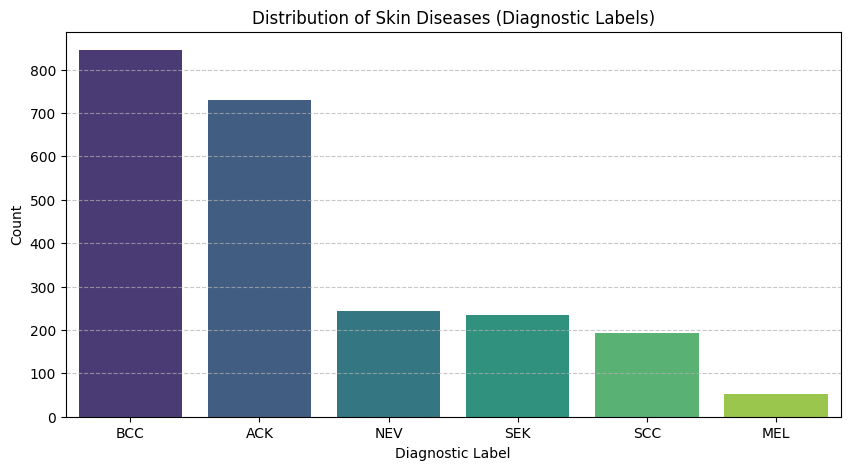

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the unique skin diseases (diagnostics) and their frequencies
diagnostic_counts = df['diagnostic'].value_counts()

print("Predicted Skin Diseases / Diagnostics in the dataset:")
for disease, count in diagnostic_counts.items():
    print(f"- {disease}: {count} occurrences")

# Visualize the distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=diagnostic_counts.index, y=diagnostic_counts.values, palette='viridis')
plt.title('Distribution of Skin Diseases (Diagnostic Labels)')
plt.xlabel('Diagnostic Label')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
print(df['diagnostic'].unique())

['NEV' 'BCC' 'ACK' 'SEK' 'SCC' 'MEL']


In [ ]:
# Count the amount of data per diagnostic label
diagnostic_counts = df['diagnostic'].value_counts()
display(diagnostic_counts)

,count
diagnostic,
BCC,845
ACK,730
NEV,244
SEK,235
SCC,192
MEL,52


In [ ]:
# In pandas, size is a property/attribute, not a function. Use df.size (no parentheses).
# Alternatively, use df.shape to get the dimensions (rows, columns).
print("Total elements (size):", df.size)
print("DataFrame shape:", df.shape)

Total elements (size): 59748
DataFrame shape: (2298, 26)


In [ ]:
df.columns

Index(['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father',
       'background_mother', 'age', 'pesticide', 'gender',
       'skin_cancer_history', 'cancer_history', 'has_piped_water',
       'has_sewage_system', 'fitspatrick', 'region', 'diameter_1',
       'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed',
       'elevation', 'img_id', 'biopsed'],
      dtype='object')

In [ ]:
df.

In [ ]:
import os, glob, pandas as pd
import kagglehub

IMG_ROOT = kagglehub.dataset_download("mahdavi1202/skin-cancer")
img_df = pd.read_csv(os.path.join(IMG_ROOT, "metadata.csv"))

path_map = {os.path.basename(p): p for p in glob.glob(f"{IMG_ROOT}/**/*.png", recursive=True)}
img_df["path"] = img_df["img_id"].map(path_map)
print(len(path_map), "images found |", img_df["path"].isna().sum(), "missing")
img_df[["img_id", "diagnostic", "path"]].head()

Using Colab cache for faster access to the 'skin-cancer' dataset.
2298 images found | 0 missing


,img_id,diagnostic,path
0,PAT_1516_1765_530.png,NEV,/kaggle/input/skin-cancer/imgs_part_3/imgs_par...
1,PAT_46_881_939.png,BCC,/kaggle/input/skin-cancer/imgs_part_1/imgs_par...
2,PAT_1545_1867_547.png,ACK,/kaggle/input/skin-cancer/imgs_part_3/imgs_par...
3,PAT_1989_4061_934.png,ACK,/kaggle/input/skin-cancer/imgs_part_3/imgs_par...
4,PAT_684_1302_588.png,BCC,/kaggle/input/skin-cancer/imgs_part_2/imgs_par...


(1089, 1089)


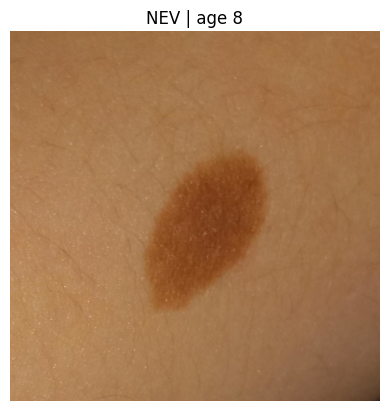

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

sample = img_df.iloc[0]
pic = Image.open(sample["path"]).convert("RGB")
plt.imshow(pic); plt.title(f'{sample["diagnostic"]} | age {sample["age"]}'); plt.axis("off")
print(pic.size)

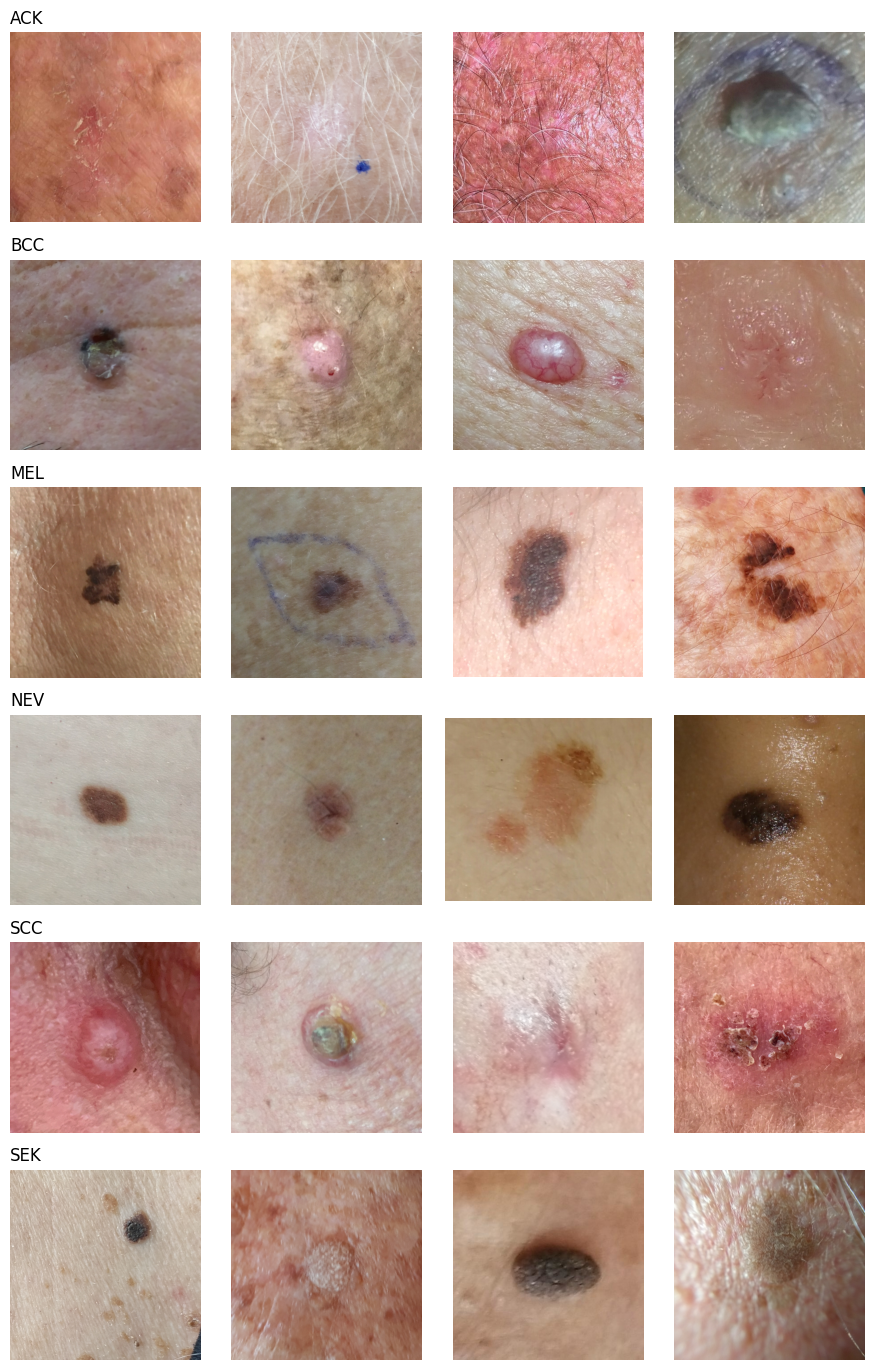

In [ ]:
LESION_CLASSES = sorted(img_df["diagnostic"].unique())
fig, axes = plt.subplots(len(LESION_CLASSES), 4, figsize=(9, 2.3 * len(LESION_CLASSES)))
for r, cls in enumerate(LESION_CLASSES):
    picks = img_df[img_df["diagnostic"] == cls].sample(4, random_state=0)["path"]
    for c, p in enumerate(picks):
        axes[r, c].imshow(Image.open(p).convert("RGB")); axes[r, c].axis("off")
    axes[r, 0].set_title(cls, loc="left")
plt.tight_layout(); plt.show()

In [ ]:
print(img_df["diagnostic"].value_counts())
print("Missing labels:", img_df["diagnostic"].isna().sum())
print("Images without a label:", len(set(path_map) - set(img_df["img_id"])))

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64
Missing labels: 0
Images without a label: 0


In [ ]:
from sklearn.model_selection import train_test_split

# Split into 70% train and 30% temp (which we will split further into val and test)
train_df, temp_df = train_test_split(
    img_df,
    test_size=0.30,
    random_state=42,
    stratify=img_df['diagnostic']
)

# Split the 30% temp into 50% validation and 50% test (15% and 15% of the total dataset)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df['diagnostic']
)

# Verify the splits and their sizes
print(f"Total dataset: {len(img_df)} samples")
print(f"Train set: {len(train_df)} samples ({len(train_df)/len(img_df):.1%})")
print(f"Validation set: {len(val_df)} samples ({len(val_df)/len(img_df):.1%})")
print(f"Test set: {len(test_df)} samples ({len(test_df)/len(img_df):.1%})")

# Display diagnostic class proportions to confirm successful stratification
print("\nTrain set target distribution:")
print(train_df['diagnostic'].value_counts(normalize=True).round(3))
print("\nTest set target distribution:")
print(test_df['diagnostic'].value_counts(normalize=True).round(3))

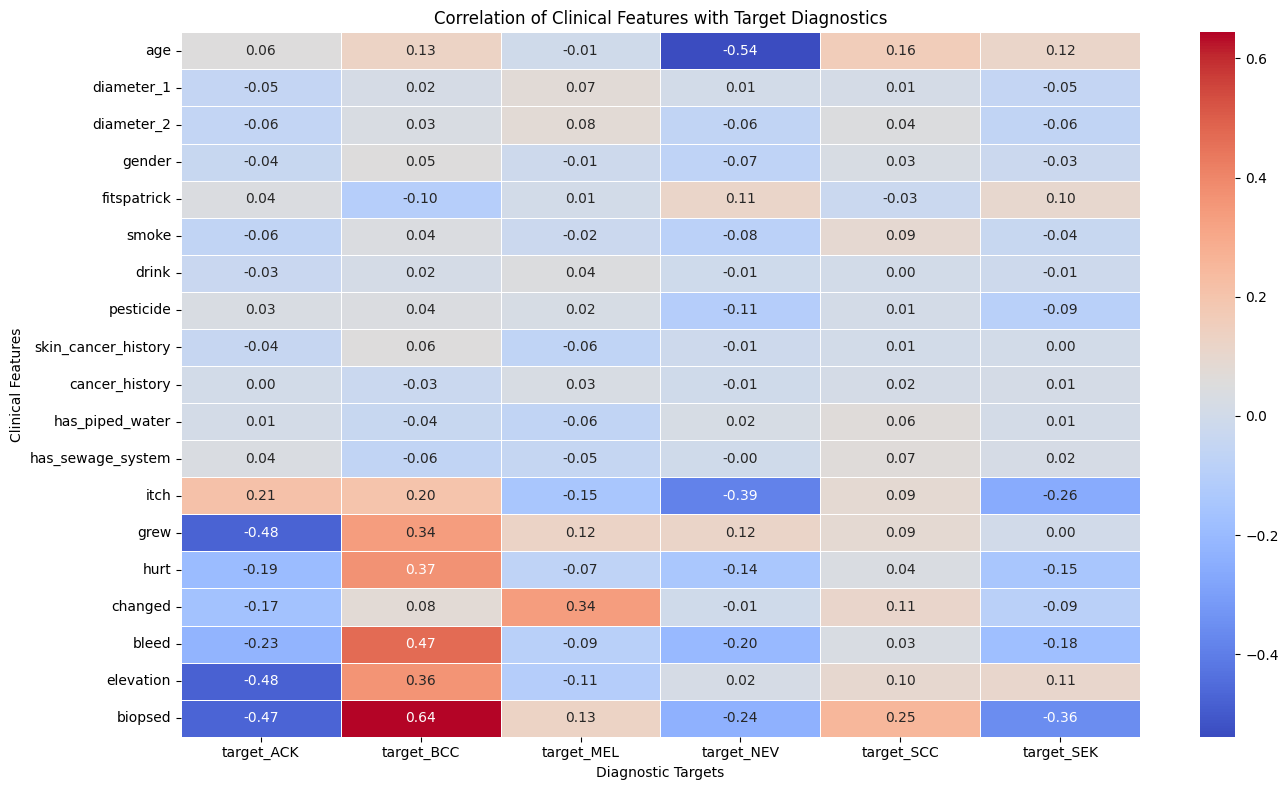

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Create a copy of the dataframe for correlation analysis
corr_df = img_df.copy()

# Convert boolean columns and boolean-like object columns to numeric (0 or 1)
bool_cols = ['smoke', 'drink', 'pesticide', 'skin_cancer_history', 'cancer_history',
             'has_piped_water', 'has_sewage_system', 'itch', 'grew', 'hurt',
             'changed', 'bleed', 'elevation', 'biopsed']

for col in bool_cols:
    if col in corr_df.columns:
        # Map string representations of booleans to actual numeric values
        corr_df[col] = corr_df[col].astype(str).str.upper().str.strip()
        corr_df[col] = corr_df[col].map({'TRUE': 1, '1': 1, '1.0': 1, 'FALSE': 0, '0': 0, '0.0': 0})

# One-hot encode the target 'diagnostic' variable to find correlation with other clinical features
diagnostic_dummies = pd.get_dummies(corr_df['diagnostic'], prefix='target')
corr_df = pd.concat([corr_df, diagnostic_dummies], axis=1)

# Map gender to numeric
corr_df['gender'] = corr_df['gender'].astype(str).str.upper().str.strip().map({'MALE': 1, 'FEMALE': 0})

# Select numerical columns and the newly encoded columns for correlation
features_to_correlate = [
    'age', 'diameter_1', 'diameter_2', 'gender', 'fitspatrick'
] + bool_cols + list(diagnostic_dummies.columns)

# Keep only valid numeric columns
numeric_corr_df = corr_df[features_to_correlate].apply(pd.to_numeric, errors='coerce')

# Compute pairwise correlation matrix
corr_matrix = numeric_corr_df.corr()

# Filter matrix to focus on correlations with the target classes
target_cols = list(diagnostic_dummies.columns)
plt.figure(figsize=(14, 8))
sns.heatmap(
    corr_matrix[target_cols].drop(target_cols, errors='ignore'),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation of Clinical Features with Target Diagnostics')
plt.ylabel('Clinical Features')
plt.xlabel('Diagnostic Targets')
plt.tight_layout()
plt.show()

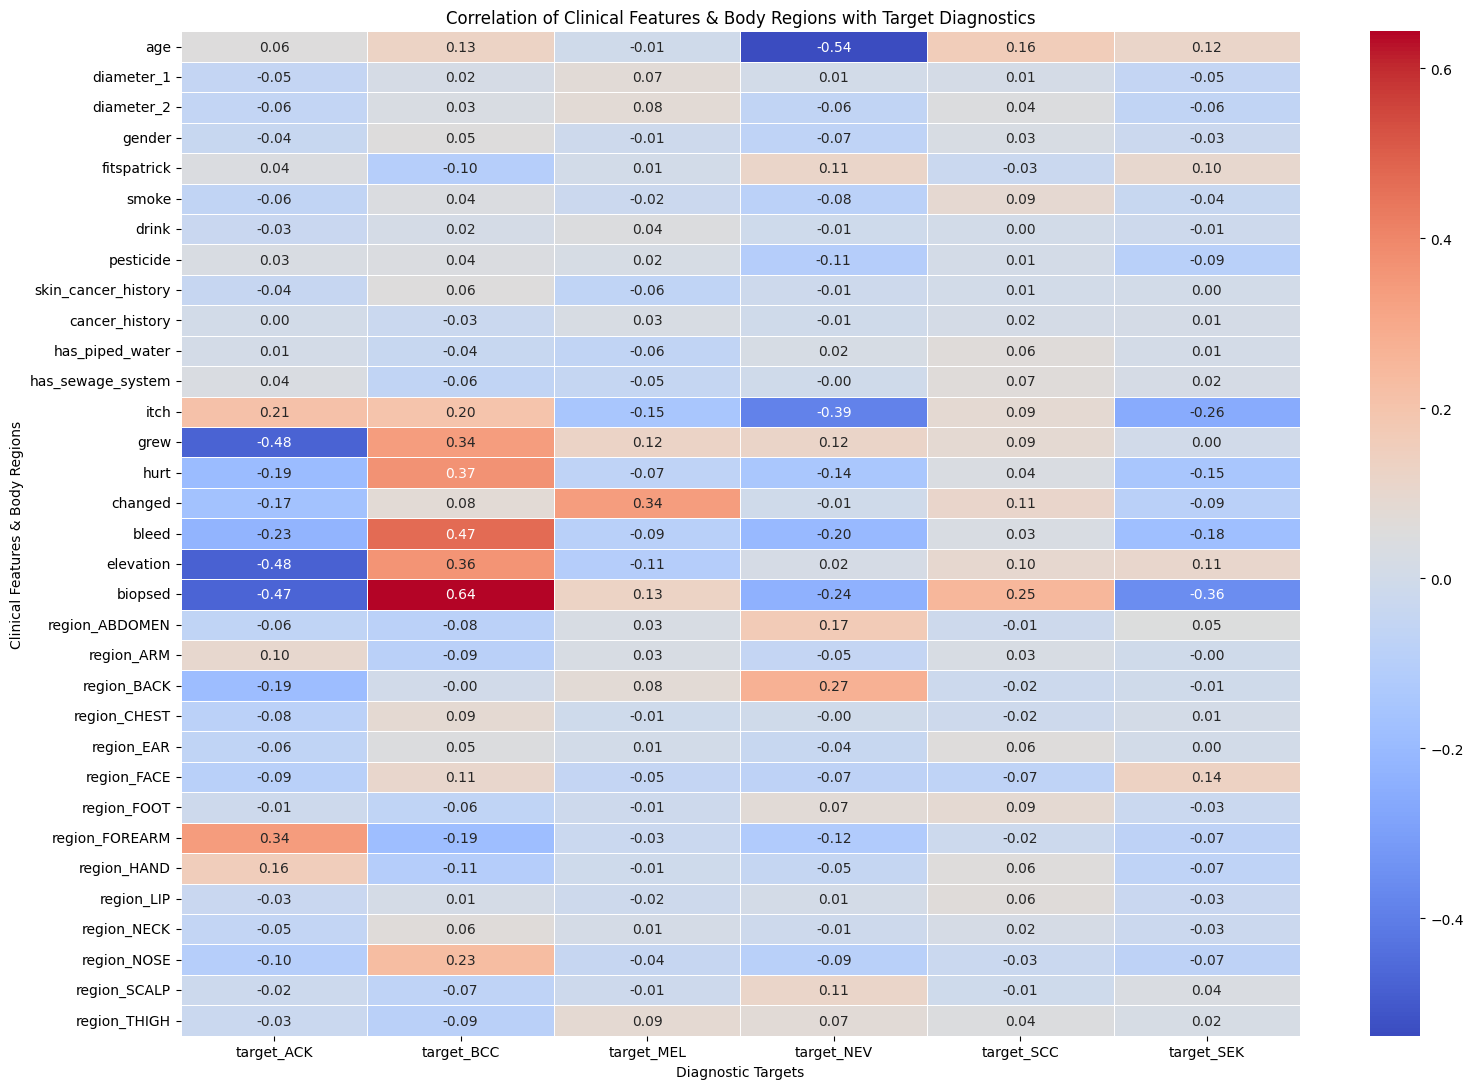

In [ ]:
# One-hot encode the 'region' categorical column as well
region_dummies = pd.get_dummies(corr_df['region'], prefix='region')
corr_df = pd.concat([corr_df, region_dummies], axis=1)

# Add the new region dummy features to our feature correlation list
extended_features = features_to_correlate + list(region_dummies.columns)

# Keep only valid numeric columns
numeric_extended_df = corr_df[extended_features].apply(pd.to_numeric, errors='coerce')

# Compute the new pairwise correlation matrix
extended_corr_matrix = numeric_extended_df.corr()

# Filter the heatmap to focus on the correlation of clinical features AND regions with target diagnostics
plt.figure(figsize=(16, 11))
sns.heatmap(
    extended_corr_matrix[target_cols].drop(target_cols, errors='ignore'),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation of Clinical Features & Body Regions with Target Diagnostics')
plt.ylabel('Clinical Features & Body Regions')
plt.xlabel('Diagnostic Targets')
plt.tight_layout()
plt.show()

In [ ]:
df['itch']

,itch
0,FALSE
1,TRUE
2,TRUE
3,TRUE
4,TRUE
...,...
2293,TRUE
2294,TRUE
2295,FALSE
2296,TRUE


In [ ]:
columns_of_interest = ['age', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'region']

# Display the data types and some unique values for the requested columns
for col in columns_of_interest:
    if col in img_df.columns:
        print(f"Column: {col:<12} | Type: {str(img_df[col].dtype):<10} | Unique values (first 5): {img_df[col].unique()[:10]}")
    else:
        print(f"Column: {col:<12} | Not found in DataFrame")

Column: age          | Type: int64      | Unique values (first 5): [ 8 55 77 75 79 53 52 74 68 58]
Column: itch         | Type: object     | Unique values (first 5): ['FALSE' 'TRUE' 'UNK']
Column: grew         | Type: object     | Unique values (first 5): ['FALSE' 'TRUE' 'UNK']
Column: hurt         | Type: object     | Unique values (first 5): ['FALSE' 'TRUE' 'UNK']
Column: changed      | Type: object     | Unique values (first 5): ['FALSE' 'TRUE' 'UNK']
Column: bleed        | Type: object     | Unique values (first 5): ['FALSE' 'TRUE' 'UNK']
Column: elevation    | Type: object     | Unique values (first 5): ['FALSE' 'TRUE' 'UNK']
Column: region       | Type: object     | Unique values (first 5): ['ARM' 'NECK' 'FACE' 'HAND' 'FOREARM' 'CHEST' 'NOSE' 'THIGH' 'SCALP' 'EAR']


In [ ]:
# Define the columns we want to check for 'UNK'
columns_to_check = ['age', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'region']

print("Count of 'UNK' (Unknown) values per column:")
print("-" * 45)
for col in columns_to_check:
    if col in img_df.columns:
        # Check for 'UNK', 'unk', or empty/whitespace values representing unknown
        unk_count = img_df[col].astype(str).str.upper().str.strip().eq('UNK').sum()
        print(f"{col:<15} : {unk_count} occurrences")
    else:
        print(f"{col:<15} : Column not found in DataFrame")

Count of 'UNK' (Unknown) values per column:
---------------------------------------------
age             : 0 occurrences
itch            : 6 occurrences
grew            : 402 occurrences
hurt            : 10 occurrences
changed         : 396 occurrences
bleed           : 6 occurrences
elevation       : 2 occurrences
region          : 0 occurrences


In [ ]:
df['region'].unique()

array(['ARM', 'NECK', 'FACE', 'HAND', 'FOREARM', 'CHEST', 'NOSE', 'THIGH',
       'SCALP', 'EAR', 'BACK', 'FOOT', 'ABDOMEN', 'LIP'], dtype=object)

In [ ]:
dfx = df[["age", "itch", "grew", "hurt", "changed", "bleed", "elevation", "region"]]

,age,itch,grew,hurt,changed,bleed,elevation,region
0,8,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,ARM
1,55,TRUE,TRUE,FALSE,TRUE,TRUE,TRUE,NECK
2,77,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,FACE
3,75,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,HAND
4,79,TRUE,TRUE,FALSE,FALSE,TRUE,TRUE,FOREARM
...,...,...,...,...,...,...,...,...
2293,73,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,HAND
2294,55,TRUE,TRUE,FALSE,TRUE,FALSE,FALSE,CHEST
2295,74,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,FOREARM
2296,58,TRUE,FALSE,FALSE,FALSE,FALSE,TRUE,FACE


In [ ]:
# Columns to clean by removing 'UNK' values
clean_cols = ['itch', 'hurt', 'bleed', 'elevation']

# Create a boolean mask where none of these columns have 'UNK' (case-insensitive)
mask = True
for col in clean_cols:
    if col in df.columns:
        mask &= df[col].astype(str).str.upper().str.strip() != 'UNK'

# Filter the dataframe and store it in dfx with the columns of interest
columns_of_interest = ['age', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'region']
dfx = df.loc[mask, columns_of_interest].copy()

# Verify the cleaning results
print(f"Original DataFrame shape: {df.shape}")
print(f"New dfx shape (after removing UNK): {dfx.shape}")
print("\nRemaining 'UNK' counts in dfx:")
for col in columns_of_interest:
    unk_count = dfx[col].astype(str).str.upper().str.strip().eq('UNK').sum()
    print(f"{col:<15} : {unk_count} occurrences")

Original DataFrame shape: (2298, 26)
New dfx shape (after removing UNK): (2279, 8)

Remaining 'UNK' counts in dfx:
age             : 0 occurrences
itch            : 0 occurrences
grew            : 384 occurrences
hurt            : 0 occurrences
changed         : 379 occurrences
bleed           : 0 occurrences
elevation       : 0 occurrences
region          : 0 occurrences


Class Distribution and Imbalance Summary:


,Count,Percentage (%)
diagnostic,,
BCC,845,36.77
ACK,730,31.77
NEV,244,10.62
SEK,235,10.23
SCC,192,8.36
MEL,52,2.26


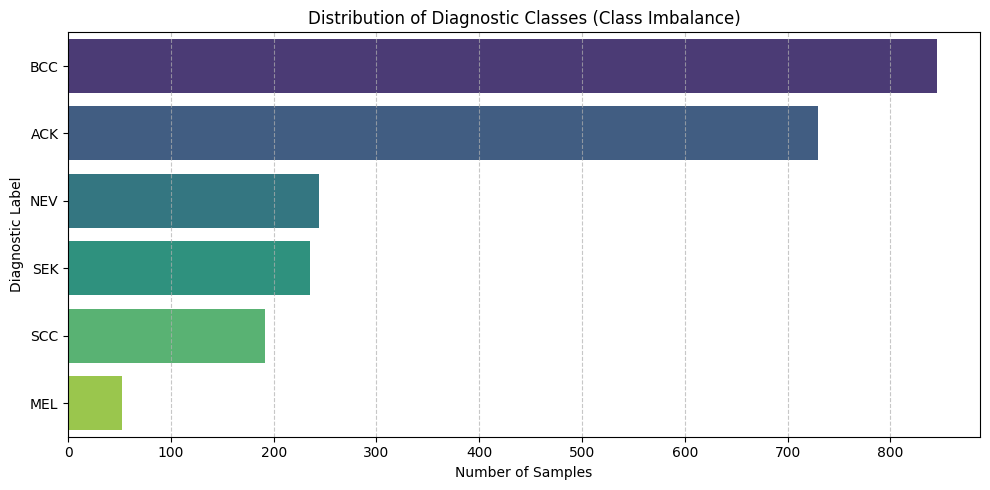

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate counts and percentages for diagnostic labels
diagnostic_counts = df['diagnostic'].value_counts()
diagnostic_percentages = df['diagnostic'].value_counts(normalize=True) * 100

# Create a summary DataFrame for display
imbalance_df = pd.DataFrame({
    'Count': diagnostic_counts,
    'Percentage (%)': diagnostic_percentages.round(2)
})

print("Class Distribution and Imbalance Summary:")
display(imbalance_df)

# Visualize class imbalance
plt.figure(figsize=(10, 5))
sns.barplot(
    x=diagnostic_counts.values,
    y=diagnostic_counts.index,
    hue=diagnostic_counts.index,
    palette='viridis',
    legend=False
)
plt.title('Distribution of Diagnostic Classes (Class Imbalance)')
plt.xlabel('Number of Samples')
plt.ylabel('Diagnostic Label')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Class Distribution and Imbalance Summary in dfx:


,Count,Percentage (%)
diagnostic,,
BCC,838,36.77
ACK,727,31.90
NEV,239,10.49
SEK,235,10.31
SCC,189,8.29
MEL,51,2.24


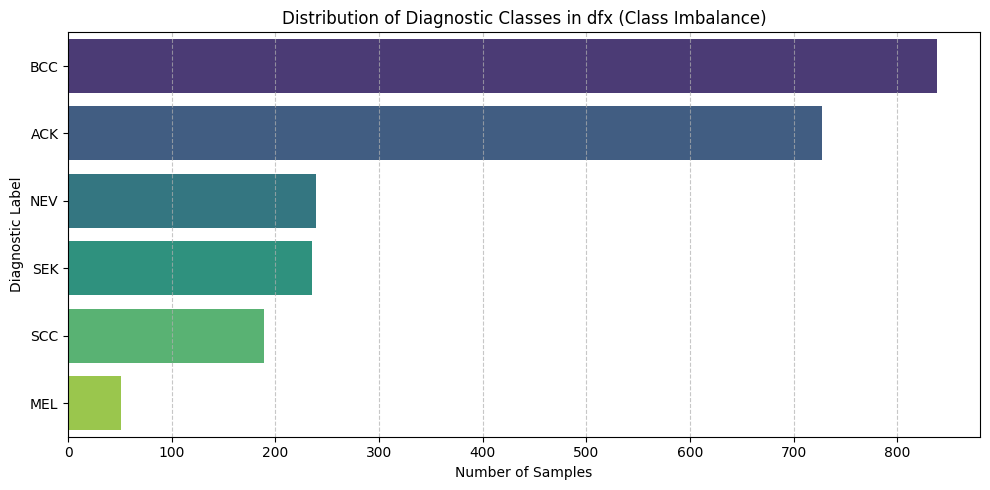

In [ ]:
# Map back or align dfx with the 'diagnostic' column from the original df
# Since dfx's index is preserved from the original df, we can map the diagnostic values easily
dfx_with_target = dfx.copy()
dfx_with_target['diagnostic'] = df.loc[dfx.index, 'diagnostic']

# Calculate counts and percentages
counts = dfx_with_target['diagnostic'].value_counts()
percentages = dfx_with_target['diagnostic'].value_counts(normalize=True) * 100

imbalance_dfx = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percentages.round(2)
})

print("Class Distribution and Imbalance Summary in dfx:")
display(imbalance_dfx)

# Visualize class imbalance
plt.figure(figsize=(10, 5))
sns.barplot(
    x=counts.values,
    y=counts.index,
    hue=counts.index,
    palette='viridis',
    legend=False
)
plt.title('Distribution of Diagnostic Classes in dfx (Class Imbalance)')
plt.xlabel('Number of Samples')
plt.ylabel('Diagnostic Label')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# 1. Install imbalanced-learn if it's not present (pre-installed in Colab, but good practice)
!pip install -q imbalanced-learn

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Create a copy of dfx for preparation
prep_df = dfx.copy()
prep_df['diagnostic'] = df.loc[dfx.index, 'diagnostic']

# Handle missing/UNK values explicitly for grows and changed columns
# Map Boolean strings to numeric representations and handle 'UNK'
for col in ['itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']:
    prep_df[col] = prep_df[col].astype(str).str.upper().str.strip()
    # Convert TRUE/FALSE to numeric, treat UNK as a dedicated category value (e.g. -1 or 2)
    # Since grew and changed have substantial UNK counts, we represent them numerically as 2
    prep_df[col] = prep_df[col].map({'TRUE': 1, 'FALSE': 0, 'UNK': 2})

# One-hot encode the categorical 'region' column
prep_df = pd.get_dummies(prep_df, columns=['region'], drop_first=False)

# Separate features (X) and target (y)
X = prep_df.drop(columns=['diagnostic'])
y = prep_df['diagnostic']

# Convert boolean True/False from pandas dummy variables to int (0/1) for compatibility with SMOTE
X = X.astype(float)

# 2. Perform 80/20 Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Original training class distribution:")
print(y_train.value_counts())

# 3. Define the exact custom SMOTE sampling strategy
# Based on your specifications:
sampling_strategy = {
    'BCC': 670,
    'ACK': 582,
    'NEV': 335,
    'SEK': 335,
    'SCC': 335,
    'MEL': 200
}

# Apply SMOTE
smote = SMOTE(sampling_strategy=sampling_strategy, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# Print final balanced dataset distribution
print("\nTraining class distribution after custom SMOTE:")
print(y_train_res.value_counts())

Original training class distribution:
diagnostic
BCC    670
ACK    582
NEV    191
SEK    188
SCC    151
MEL     41
Name: count, dtype: int64

Training class distribution after custom SMOTE:
diagnostic
BCC    670
ACK    582
SCC    335
NEV    335
SEK    335
MEL    200
Name: count, dtype: int64


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

# 1. Prepare clean base data mapped with patient_id and diagnostic
clean_df = img_df.loc[dfx.index].copy()

# 2. Instantiate StratifiedGroupKFold with 5 folds
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Initialize fold column
clean_df['fold'] = -1

# Extract features, targets and patient groups
X_dummy = np.zeros(len(clean_df))
y_labels = clean_df['diagnostic']
groups = clean_df['patient_id']

# Assign fold IDs
for fold_idx, (train_idx, val_idx) in enumerate(sgkf.split(X_dummy, y_labels, groups)):
    clean_df.iloc[val_idx, clean_df.columns.get_loc('fold')] = fold_idx

# 3. Save splits to a CSV file
splits_path = 'splits.csv'
clean_df[['img_id', 'patient_id', 'diagnostic', 'fold']].to_csv(splits_path, index=False)
print(f"Successfully saved split folds to {splits_path}")

# 4. Show distribution of classes across folds to verify stratification
fold_distribution = pd.crosstab(clean_df['fold'], clean_df['diagnostic'])
print("\nClass distribution across the 5 folds:")
display(fold_distribution)

# Verify patient overlap between folds (should be 0)
overlap_found = False
for i in range(5):
    for j in range(i+1, 5):
        patients_i = set(clean_df[clean_df['fold'] == i]['patient_id'])
        patients_j = set(clean_df[clean_df['fold'] == j]['patient_id'])
        overlap = patients_i.intersection(patients_j)
        if len(overlap) > 0:
            overlap_found = True
            print(f"Overlap found between fold {i} and {j}!")

if not overlap_found:
    print("\nSuccess: Confirmed zero patient overlap between folds.")

Successfully saved split folds to splits.csv

Class distribution across the 5 folds:


diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
fold,,,,,,
0,152,150,7,52,33,55
1,151,179,9,45,51,36
2,144,175,9,36,39,45
3,128,184,16,55,27,49
4,152,150,10,51,39,50



Success: Confirmed zero patient overlap between folds.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import f1_score, recall_score
from imblearn.over_sampling import SMOTE, RandomOverSampler
import warnings

warnings.filterwarnings('ignore')

# 1. Load splits mapping
splits_df = pd.read_csv('splits.csv')

# 2. Reconstruct features (X) and numeric labels (y) aligned with the clean indices
prep_df = dfx.copy()
prep_df['diagnostic'] = df.loc[dfx.index, 'diagnostic']

# Map boolean-like columns to numeric values
for col in ['itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']:
    prep_df[col] = prep_df[col].astype(str).str.upper().str.strip()
    prep_df[col] = prep_df[col].map({'TRUE': 1, 'FALSE': 0, 'UNK': 2})

# One-hot encode clinical body regions
prep_df = pd.get_dummies(prep_df, columns=['region'], drop_first=False)

X_all = prep_df.drop(columns=['diagnostic']).astype(float)

# Map diagnostic classes to numeric labels for model compatibility
class_mapping = {label: i for i, label in enumerate(sorted(prep_df['diagnostic'].unique()))}
inv_class_mapping = {i: label for label, i in class_mapping.items()}
y_all = prep_df['diagnostic'].map(class_mapping)

# 3. Setup evaluation structures
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss')
}

balancing_setups = ['Unbalanced', 'Standard SMOTE', 'Custom SMOTE', 'Random Oversampling']
results = {model_name: {setup: {'macro_f1': [], 'recalls': []} for setup in balancing_setups} for model_name in models}

# 4. Run 5-Fold Evaluation
for fold_id in range(5):
    # Extract indices based on splits.csv
    train_indices = splits_df[splits_df['fold'] != fold_id].index
    val_indices = splits_df[splits_df['fold'] == fold_id].index

    X_train_fold, y_train_fold = X_all.iloc[train_indices], y_all.iloc[train_indices]
    X_val_fold, y_val_fold = X_all.iloc[val_indices], y_all.iloc[val_indices]

    # Count original classes in this training fold
    class_counts = y_train_fold.value_counts()
    majority_count = class_counts.max()

    for setup in balancing_setups:
        if setup == 'Unbalanced':
            X_res, y_res = X_train_fold, y_train_fold

        elif setup == 'Standard SMOTE':
            # Equalize all classes to the majority count
            sm = SMOTE(random_state=42)
            X_res, y_res = sm.fit_resample(X_train_fold, y_train_fold)

        elif setup == 'Custom SMOTE':
            # Target profile scaled dynamically for the fold size
            target_profile = {'BCC': 670, 'ACK': 582, 'NEV': 335, 'SEK': 335, 'SCC': 335, 'MEL': 200}
            total_target = sum(target_profile.values())

            fold_strat_strategy = {}
            for label, target_val in target_profile.items():
                cls_idx = class_mapping[label]
                # Scale original ratio to current training split size
                proportion = target_val / total_target
                desired_size = int(proportion * len(y_train_fold) * 1.35)
                # Ensure SMOTE only oversamples
                fold_strat_strategy[cls_idx] = max(desired_size, class_counts.get(cls_idx, 0))

            sm_custom = SMOTE(sampling_strategy=fold_strat_strategy, random_state=42, k_neighbors=min(3, class_counts.min() - 1))
            X_res, y_res = sm_custom.fit_resample(X_train_fold, y_train_fold)

        elif setup == 'Random Oversampling':
            ros = RandomOverSampler(random_state=42)
            X_res, y_res = ros.fit_resample(X_train_fold, y_train_fold)

        # Train and evaluate models
        for model_name, clf in models.items():
            clf.fit(X_res, y_res)
            preds = clf.predict(X_val_fold)

            # Metrics
            macro_f1 = f1_score(y_val_fold, preds, average='macro')
            recalls = recall_score(y_val_fold, preds, average=None, labels=sorted(list(class_mapping.values())))

            results[model_name][setup]['macro_f1'].append(macro_f1)
            results[model_name][setup]['recalls'].append(recalls)

# 5. Format and present results
for model_name in models:
    print(f"\n=== Performance Summary for {model_name} ===")
    for setup in balancing_setups:
        f1_list = results[model_name][setup]['macro_f1']
        recall_matrix = np.array(results[model_name][setup]['recalls']) # shape (5, num_classes)

        mean_f1 = np.mean(f1_list)
        std_f1 = np.std(f1_list)

        mean_recalls = np.mean(recall_matrix, axis=0)
        std_recalls = np.std(recall_matrix, axis=0)

        print(f"\nSetup: {setup}")
        print(f"  Macro F1: {mean_f1:.4f}  {std_f1:.4f}")
        print("  Per-class Recall:")
        for cls_idx, cls_name in inv_class_mapping.items():
            print(f"    {cls_name:<4}: {mean_recalls[cls_idx]:.4f}  {std_recalls[cls_idx]:.4f}")


=== Performance Summary for Logistic Regression ===

Setup: Unbalanced
  Macro F1: 0.5351  0.0316
  Per-class Recall:
    ACK : 0.8584  0.0137
    BCC : 0.8063  0.0582
    MEL : 0.1494  0.1048
    NEV : 0.7506  0.0621
    SCC : 0.1198  0.0859
    SEK : 0.5002  0.0593

Setup: Standard SMOTE
  Macro F1: 0.5352  0.0156
  Per-class Recall:
    ACK : 0.7339  0.0254
    BCC : 0.5748  0.0688
    MEL : 0.4149  0.1006
    NEV : 0.7354  0.0888
    SCC : 0.4265  0.1593
    SEK : 0.6496  0.0757

Setup: Custom SMOTE
  Macro F1: 0.5570  0.0296
  Per-class Recall:
    ACK : 0.8216  0.0129
    BCC : 0.7117  0.0533
    MEL : 0.3135  0.0898
    NEV : 0.7223  0.0821
    SCC : 0.2883  0.1233
    SEK : 0.5495  0.0690

Setup: Random Oversampling
  Macro F1: 0.5380  0.0189
  Per-class Recall:
    ACK : 0.7213  0.0282
    BCC : 0.5551  0.0586
    MEL : 0.4399  0.1299
    NEV : 0.7793  0.1013
    SCC : 0.4137  0.1431
    SEK : 0.6824  0.0720

=== Performance Summary for Random Fore

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import precision_recall_fscore_support
import warnings

warnings.filterwarnings('ignore')

# We will collect comprehensive metrics (Precision, Recall, F1) for the best performing configurations:
# Logistic Regression and XGBoost with Custom SMOTE.
target_setups = [('Logistic Regression', 'Custom SMOTE'), ('XGBoost', 'Custom SMOTE')]

for model_name, setup in target_setups:
    clf_base = models[model_name]

    # Lists to store metrics across 5 folds
    fold_precisions = []
    fold_recalls = []
    fold_f1s = []

    for fold_id in range(5):
        train_indices = splits_df[splits_df['fold'] != fold_id].index
        val_indices = splits_df[splits_df['fold'] == fold_id].index

        X_train_fold, y_train_fold = X_all.iloc[train_indices], y_all.iloc[train_indices]
        X_val_fold, y_val_fold = X_all.iloc[val_indices], y_all.iloc[val_indices]

        # Apply Custom SMOTE balancing
        class_counts = y_train_fold.value_counts()
        target_profile = {'BCC': 670, 'ACK': 582, 'NEV': 335, 'SEK': 335, 'SCC': 335, 'MEL': 200}
        total_target = sum(target_profile.values())

        fold_strat_strategy = {}
        for label, target_val in target_profile.items():
            cls_idx = class_mapping[label]
            proportion = target_val / total_target
            desired_size = int(proportion * len(y_train_fold) * 1.35)
            fold_strat_strategy[cls_idx] = max(desired_size, class_counts.get(cls_idx, 0))

        sm_custom = SMOTE(sampling_strategy=fold_strat_strategy, random_state=42, k_neighbors=min(3, class_counts.min() - 1))
        X_res, y_res = sm_custom.fit_resample(X_train_fold, y_train_fold)

        # Train & Predict
        clf_base.fit(X_res, y_res)
        preds = clf_base.predict(X_val_fold)

        # Calculate Precision, Recall, and F1-score simultaneously for all classes
        p, r, f, _ = precision_recall_fscore_support(
            y_val_fold, preds, labels=sorted(list(class_mapping.values())), zero_division=0
        )

        fold_precisions.append(p)
        fold_recalls.append(r)
        fold_f1s.append(f)

    # Calculate mean and std over the 5 folds
    mean_p, std_p = np.mean(fold_precisions, axis=0), np.std(fold_precisions, axis=0)
    mean_r, std_r = np.mean(fold_recalls, axis=0), np.std(fold_recalls, axis=0)
    mean_f, std_f = np.mean(fold_f1s, axis=0), np.std(fold_f1s, axis=0)

    print(f"\n{'='*55}\n{model_name} with {setup} (5-Fold Mean  Std)\n{'='*55}")
    print(f"{'Class':<6} | {'Precision':<17} | {'Recall':<17} | {'F1-Score':<17}")
    print("-"*60)
    for cls_idx, cls_name in inv_class_mapping.items():
        print(f"{cls_name:<6} | {mean_p[cls_idx]:.3f}  {std_p[cls_idx]:.3f} | {mean_r[cls_idx]:.3f}  {std_r[cls_idx]:.3f} | {mean_f[cls_idx]:.3f}  {std_f[cls_idx]:.3f}")



Logistic Regression with Custom SMOTE (5-Fold Mean  Std)
Class  | Precision         | Recall            | F1-Score         
------------------------------------------------------------
ACK    | 0.775  0.029 | 0.822  0.013 | 0.797  0.015
BCC    | 0.764  0.018 | 0.712  0.053 | 0.736  0.030
MEL    | 0.278  0.194 | 0.314  0.090 | 0.282  0.139
NEV    | 0.699  0.065 | 0.722  0.082 | 0.709  0.064
SCC    | 0.331  0.064 | 0.288  0.123 | 0.301  0.090
SEK    | 0.490  0.053 | 0.549  0.069 | 0.516  0.053

XGBoost with Custom SMOTE (5-Fold Mean  Std)
Class  | Precision         | Recall            | F1-Score         
------------------------------------------------------------
ACK    | 0.743  0.031 | 0.794  0.037 | 0.767  0.024
BCC    | 0.721  0.022 | 0.753  0.047 | 0.735  0.023
MEL    | 0.405  0.057 | 0.371  0.072 | 0.381  0.045
NEV    | 0.697  0.027 | 0.730  0.096 | 0.711  0.059
SCC    | 0.306  0.112 | 0.187  0.079 | 0.222  0.075
SEK    | 0.475  0.028 | 0.438  

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support
import warnings

warnings.filterwarnings('ignore')

# --- SOLUTION 1: Feature Engineering (Clinical Interactions) ---
X_engineered = X_all.copy()

# Create risk interaction multipliers
# Clinical symptoms are significantly more indicative of malignancy as age increases
X_engineered['age_x_bleed'] = X_engineered['age'] * X_engineered['bleed']
X_engineered['age_x_grew'] = X_engineered['age'] * X_engineered['grew']
X_engineered['age_x_changed'] = X_engineered['age'] * X_engineered['changed']
X_engineered['elevation_x_bleed'] = X_engineered['elevation'] * X_engineered['bleed']

# --- SOLUTION 2: Cost-Sensitive Learning (Class Weights) ---
# Calculate inverse frequency class weights to heavily penalize errors on rare classes (MEL, SCC)
class_counts_total = y_all.value_counts()
total_samples = len(y_all)
num_classes = len(class_counts_total)

# Compute balanced weights
weights = {cls: total_samples / (num_classes * count) for cls, count in class_counts_total.items()}
print("Calculated Class Penalty Weights:")
for cls_idx, w in weights.items():
    print(f"  {inv_class_mapping[cls_idx]:<4}: {w:.2f}x penalty multiplier")

# Evaluate the engineered & cost-sensitive Logistic Regression across the 5 folds
fold_precisions = []
fold_recalls = []
fold_f1s = []

for fold_id in range(5):
    train_indices = splits_df[splits_df['fold'] != fold_id].index
    val_indices = splits_df[splits_df['fold'] == fold_id].index

    X_train_fold = X_engineered.iloc[train_indices]
    y_train_fold = y_all.iloc[train_indices]
    X_val_fold = X_engineered.iloc[val_indices]
    y_val_fold = y_all.iloc[val_indices]

    # Initialize Logistic Regression with our custom class penalties
    clf_balanced = LogisticRegression(class_weight=weights, max_iter=2000, random_state=42)

    # Train & Predict
    clf_balanced.fit(X_train_fold, y_train_fold)
    preds = clf_balanced.predict(X_val_fold)

    # Calculate Metrics
    p, r, f, _ = precision_recall_fscore_support(
        y_val_fold, preds, labels=sorted(list(class_mapping.values())), zero_division=0
    )

    fold_precisions.append(p)
    fold_recalls.append(r)
    fold_f1s.append(f)

# Compute 5-Fold average metrics
mean_p, std_p = np.mean(fold_precisions, axis=0), np.std(fold_precisions, axis=0)

mean_r, std_r = np.mean(fold_recalls, axis=0), np.std(fold_recalls, axis=0)
mean_f, std_f = np.mean(fold_f1s, axis=0), np.std(fold_f1s, axis=0)

print(f"\n{'='*55}\nLogistic Regression with Feature Engineering + Class Weights\n{'='*55}")
print(f"{'Class':<6} | {'Precision':<17} | {'Recall':<17} | {'F1-Score':<17}")
print("-"*60)
for cls_idx, cls_name in inv_class_mapping.items():
    print(f"{cls_name:<6} | {mean_p[cls_idx]:.3f}  {std_p[cls_idx]:.3f} | {mean_r[cls_idx]:.3f}  {std_r[cls_idx]:.3f} | {mean_f[cls_idx]:.3f}  {std_f[cls_idx]:.3f}")


Calculated Class Penalty Weights:
  BCC : 0.45x penalty multiplier
  ACK : 0.52x penalty multiplier
  NEV : 1.59x penalty multiplier
  SEK : 1.62x penalty multiplier
  SCC : 2.01x penalty multiplier
  MEL : 7.45x penalty multiplier

Logistic Regression with Feature Engineering + Class Weights
Class  | Precision         | Recall            | F1-Score         
------------------------------------------------------------
ACK    | 0.804  0.027 | 0.708  0.023 | 0.753  0.019
BCC    | 0.829  0.041 | 0.562  0.059 | 0.668  0.046
MEL    | 0.168  0.098 | 0.427  0.113 | 0.234  0.107
NEV    | 0.693  0.049 | 0.779  0.100 | 0.730  0.060
SCC    | 0.256  0.045 | 0.405  0.111 | 0.305  0.043
SEK    | 0.413  0.046 | 0.649  0.034 | 0.503  0.032


In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import precision_recall_fscore_support
from imblearn.over_sampling import SMOTE
import warnings

warnings.filterwarnings('ignore')

# 1. Load splits mapping
splits_df = pd.read_csv('splits.csv')

# 2. Reconstruct features (X) and numeric labels (y)
prep_df = dfx.copy()
prep_df['diagnostic'] = df.loc[dfx.index, 'diagnostic']

for col in ['itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']:
    prep_df[col] = prep_df[col].astype(str).str.upper().str.strip()
    prep_df[col] = prep_df[col].map({'TRUE': 1, 'FALSE': 0, 'UNK': 2})

prep_df = pd.get_dummies(prep_df, columns=['region'], drop_first=False)
X_all = prep_df.drop(columns=['diagnostic']).astype(float)

class_mapping = {label: i for i, label in enumerate(sorted(prep_df['diagnostic'].unique()))}
inv_class_mapping = {i: label for label, i in class_mapping.items()}
y_all = prep_df['diagnostic'].map(class_mapping)

# 3. Setup models
eval_models = {
    'Logistic Regression (Standard SMOTE)': LogisticRegression(max_iter=1000, random_state=42),
    'XGBoost (Standard SMOTE)': XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss')
}

# 4. Evaluate with 5-Fold Cross-Validation
for model_name, clf in eval_models.items():
    fold_precisions = []
    fold_recalls = []
    fold_f1s = []

    for fold_id in range(5):
        train_indices = splits_df[splits_df['fold'] != fold_id].index
        val_indices = splits_df[splits_df['fold'] == fold_id].index

        X_train_fold, y_train_fold = X_all.iloc[train_indices], y_all.iloc[train_indices]
        X_val_fold, y_val_fold = X_all.iloc[val_indices], y_all.iloc[val_indices]

        # Standard SMOTE: Oversample all classes up to the majority class count
        sm = SMOTE(random_state=42)
        X_res, y_res = sm.fit_resample(X_train_fold, y_train_fold)

        # Train & Predict
        clf.fit(X_res, y_res)
        preds = clf.predict(X_val_fold)

        # Calculate Metrics
        p, r, f, _ = precision_recall_fscore_support(
            y_val_fold, preds, labels=sorted(list(class_mapping.values())), zero_division=0
        )
        fold_precisions.append(p)
        fold_recalls.append(r)
        fold_f1s.append(f)

    # Calculate mean and std
    mean_p, std_p = np.mean(fold_precisions, axis=0), np.std(fold_precisions, axis=0)
    mean_r, std_r = np.mean(fold_recalls, axis=0), np.std(fold_recalls, axis=0)
    mean_f, std_f = np.mean(fold_f1s, axis=0), np.std(fold_f1s, axis=0)

    print(f"\n{'='*65}\n{model_name} (5-Fold Mean \u00b1 Std)\n{'='*65}")
    print(f"{'Class':<6} | {'Precision':<17} | {'Recall':<17} | {'F1-Score':<17}")
    print("-"*65)
    for cls_idx, cls_name in inv_class_mapping.items():
        print(f"{cls_name:<6} | {mean_p[cls_idx]:.3f} \u00b1 {std_p[cls_idx]:.3f} | {mean_r[cls_idx]:.3f} \u00b1 {std_r[cls_idx]:.3f} | {mean_f[cls_idx]:.3f} \u00b1 {std_f[cls_idx]:.3f}")



Logistic Regression (Standard SMOTE) (5-Fold Mean ± Std)
Class  | Precision         | Recall            | F1-Score         
-----------------------------------------------------------------
ACK    | 0.808 ± 0.045 | 0.734 ± 0.025 | 0.768 ± 0.021
BCC    | 0.825 ± 0.036 | 0.575 ± 0.069 | 0.674 ± 0.046
MEL    | 0.175 ± 0.082 | 0.415 ± 0.101 | 0.240 ± 0.087
NEV    | 0.675 ± 0.042 | 0.735 ± 0.089 | 0.700 ± 0.044
SCC    | 0.270 ± 0.030 | 0.426 ± 0.159 | 0.320 ± 0.052
SEK    | 0.421 ± 0.053 | 0.650 ± 0.076 | 0.508 ± 0.052

XGBoost (Standard SMOTE) (5-Fold Mean ± Std)
Class  | Precision         | Recall            | F1-Score         
-----------------------------------------------------------------
ACK    | 0.749 ± 0.035 | 0.796 ± 0.028 | 0.771 ± 0.021
BCC    | 0.717 ± 0.032 | 0.731 ± 0.052 | 0.722 ± 0.028
MEL    | 0.411 ± 0.137 | 0.382 ± 0.154 | 0.384 ± 0.129
NEV    | 0.645 ± 0.031 | 0.713 ± 0.074 | 0.677 ± 0.050
SCC    | 0.215 ± 0.140 | 0.135 ± 0.076 | 0.161 ± 0.091
SEK    | 0.462 ± 0.038 | 

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_fscore_support
import warnings

warnings.filterwarnings('ignore')

# 1. Load splits mapping
splits_df = pd.read_csv('splits.csv')

# 2. Use the engineered features we constructed earlier
# X_engineered contains the interaction terms like age * bleed, age * grew, age * changed, etc.
# y_all contains numeric labels mapped from class_mapping

# Calculate inverse frequency class weights to heavily penalize errors on rare classes (MEL, SCC)
class_counts_total = y_all.value_counts()
total_samples = len(y_all)
num_classes = len(class_counts_total)

# Compute balanced weights
weights = {cls: total_samples / (num_classes * count) for cls, count in class_counts_total.items()}

print("Applying Clinical Features & Class Weights to Random Forest...")

# 3. Setup structures to evaluate Random Forest across 5 folds
fold_precisions = []
fold_recalls = []
fold_f1s = []

for fold_id in range(5):
    train_indices = splits_df[splits_df['fold'] != fold_id].index
    val_indices = splits_df[splits_df['fold'] == fold_id].index

    X_train_fold = X_engineered.iloc[train_indices]
    y_train_fold = y_all.iloc[train_indices]
    X_val_fold = X_engineered.iloc[val_indices]
    y_val_fold = y_all.iloc[val_indices]

    # Random Forest with class_weight='balanced' (uses inverse frequency automatically inside trees)
    # or we can pass our custom calculated weights dict
    clf_rf = RandomForestClassifier(class_weight=weights, random_state=42)

    # Train & Predict
    clf_rf.fit(X_train_fold, y_train_fold)
    preds = clf_rf.predict(X_val_fold)

    # Calculate Metrics
    p, r, f, _ = precision_recall_fscore_support(
        y_val_fold, preds, labels=sorted(list(class_mapping.values())), zero_division=0
    )

    fold_precisions.append(p)
    fold_recalls.append(r)
    fold_f1s.append(f)

# Compute 5-Fold average metrics
mean_p, std_p = np.mean(fold_precisions, axis=0), np.std(fold_precisions, axis=0)
mean_r, std_r = np.mean(fold_recalls, axis=0), np.std(fold_recalls, axis=0)
mean_f, std_f = np.mean(fold_f1s, axis=0), np.std(fold_f1s, axis=0)

print(f"\n{'='*65}\nRandom Forest with Feature Engineering + Class Weights (5-Fold Mean \u00b1 Std)\n{'='*65}")
print(f"{'Class':<6} | {'Precision':<17} | {'Recall':<17} | {'F1-Score':<17}")
print("-"*65)
for cls_idx, cls_name in inv_class_mapping.items():
    print(f"{cls_name:<6} | {mean_p[cls_idx]:.3f} \u00b1 {std_p[cls_idx]:.3f} | {mean_r[cls_idx]:.3f} \u00b1 {std_r[cls_idx]:.3f} | {mean_f[cls_idx]:.3f} \u00b1 {std_f[cls_idx]:.3f}")


Applying Clinical Features & Class Weights to Random Forest...

Random Forest with Feature Engineering + Class Weights (5-Fold Mean ± Std)
Class  | Precision         | Recall            | F1-Score         
-----------------------------------------------------------------
ACK    | 0.727 ± 0.046 | 0.739 ± 0.056 | 0.733 ± 0.047
BCC    | 0.669 ± 0.016 | 0.729 ± 0.049 | 0.697 ± 0.027
MEL    | 0.299 ± 0.073 | 0.282 ± 0.143 | 0.275 ± 0.103
NEV    | 0.703 ± 0.032 | 0.713 ± 0.092 | 0.706 ± 0.059
SCC    | 0.194 ± 0.087 | 0.113 ± 0.065 | 0.139 ± 0.071
SEK    | 0.434 ± 0.053 | 0.432 ± 0.097 | 0.427 ± 0.056
